АНАЛИЗ ВРЕМЕННОГО РЯДА НА СЕЗОННОСТЬ

In [2]:
import pandas as pd
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt
df = pd.read_csv(r"C:\курсовая_семичевский\data\raw\moex_stocks_panel.csv")
df_ALRS = df[df['ticker'] == 'ALRS']
df_ALRS.dropna()

df['begin'] = pd.to_datetime(df['begin'])
df = df.set_index('begin')
final_tickers = ['SBER', 'GAZP', 'VTBR', 'LKOH', 'ROSN', 'PLZL', 'GMKN',
                 'SELG', 'RUAL', 'MGNT', 'ALRS', 'MTSS', 'IRAO']

df = df[df['ticker'].isin(final_tickers)].copy()

df_month = df.groupby('ticker').resample('ME').last().reset_index()

df_month = df_month.dropna()
df_month


,ticker,begin,open,close,high,low,value,volume
0,ALRS,2015-01-31,76.560,78.490,80.260,76.560,5.009149e+08,6414000
1,ALRS,2015-02-28,69.250,68.500,70.460,67.320,4.830561e+08,7065700
2,ALRS,2015-03-31,71.330,72.000,72.790,69.750,4.500374e+08,6335800
3,ALRS,2015-04-30,69.280,68.390,69.280,67.200,2.716412e+08,3992900
4,ALRS,2015-05-31,68.490,63.250,69.250,63.250,8.131017e+08,12201200
...,...,...,...,...,...,...,...,...
1839,VTBR,2026-06-30,74.390,73.825,75.990,73.155,4.886964e+09,65352594
1840,VTBR,2026-07-31,56.270,56.390,56.860,55.890,3.026224e+09,53789264
1841,VTBR,2026-08-31,50.350,51.865,51.990,50.205,3.348171e+09,65378095
1842,VTBR,2026-09-30,51.855,52.250,53.000,51.610,3.028152e+09,58012437


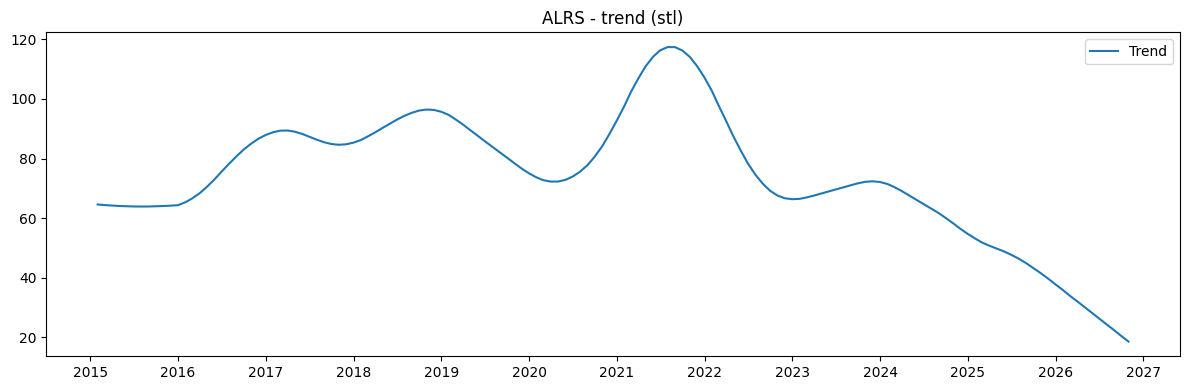

In [8]:
def check_trend_stl(ticker, df):
    from statsmodels.tsa.seasonal import STL
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates

    series = df[df['ticker'] == ticker].set_index('begin')['open']
    series = series.asfreq('ME')

    stl = STL(series, period=12)
    result = stl.fit()

    trend = result.trend

    plt.figure(figsize=(12, 4))
    plt.plot(trend, label='Trend')
    plt.legend(loc='upper right')
    plt.title(f'{ticker} - trend (stl)')
    plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    plt.show()
check_trend_stl('ALRS', df_month)

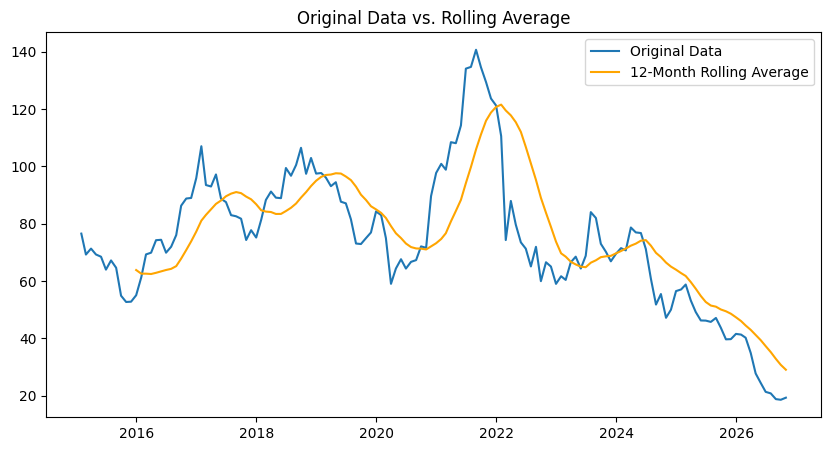

In [4]:
# Расчет скользящего среднего за 12 месяцев
df_month_alrs = df_month[df_month['ticker'] == 'ALRS'].copy()
df_month_alrs['rolling_avg'] = df_month_alrs['open'].rolling(window=12).mean()

plt.figure(figsize=(10, 5))
plt.plot(df_month_alrs['begin'], df_month_alrs['open'], label='Original Data')
plt.plot(df_month_alrs['begin'], df_month_alrs['rolling_avg'], label='12-Month Rolling Average', color='orange')
plt.title('Original Data vs. Rolling Average')
plt.legend()
plt.show()

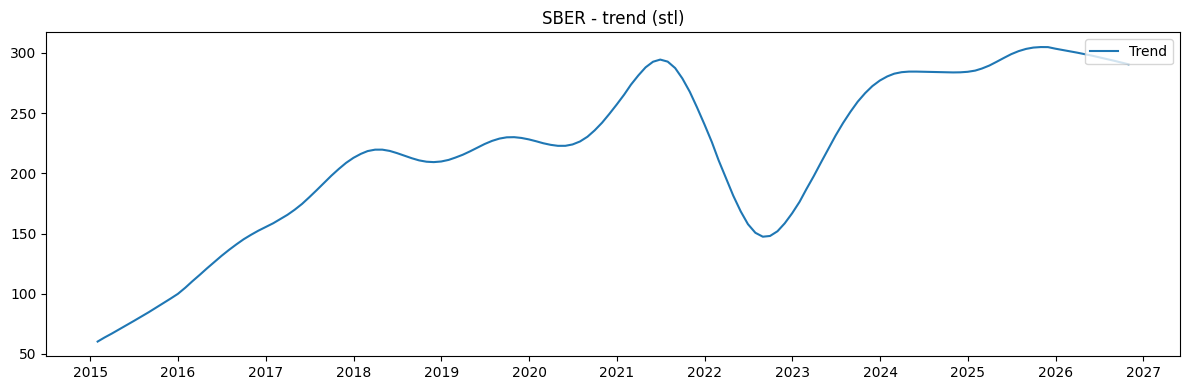

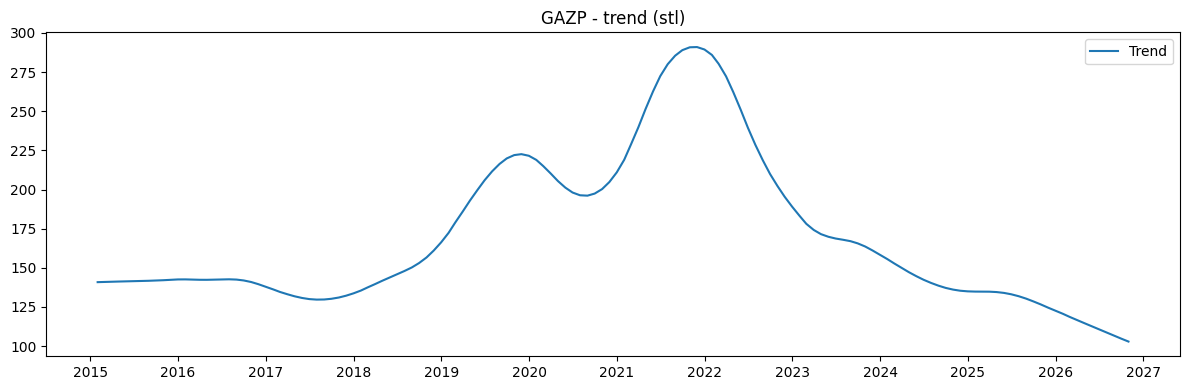

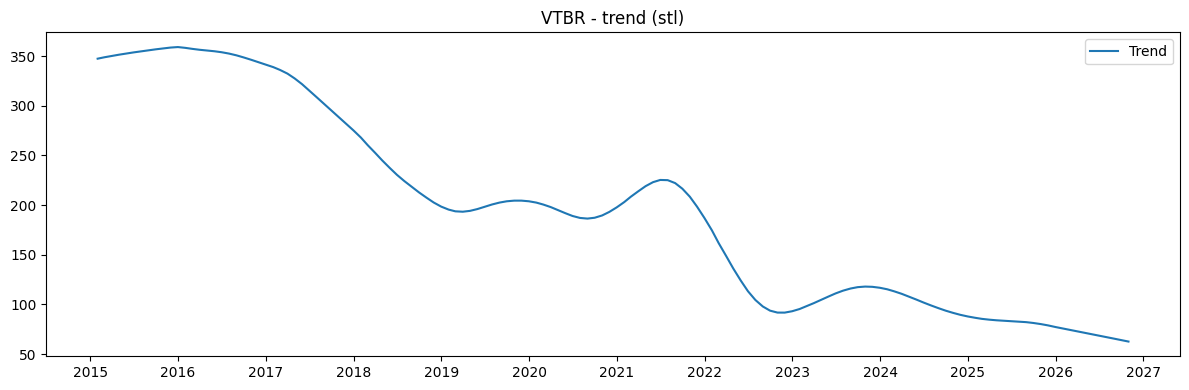

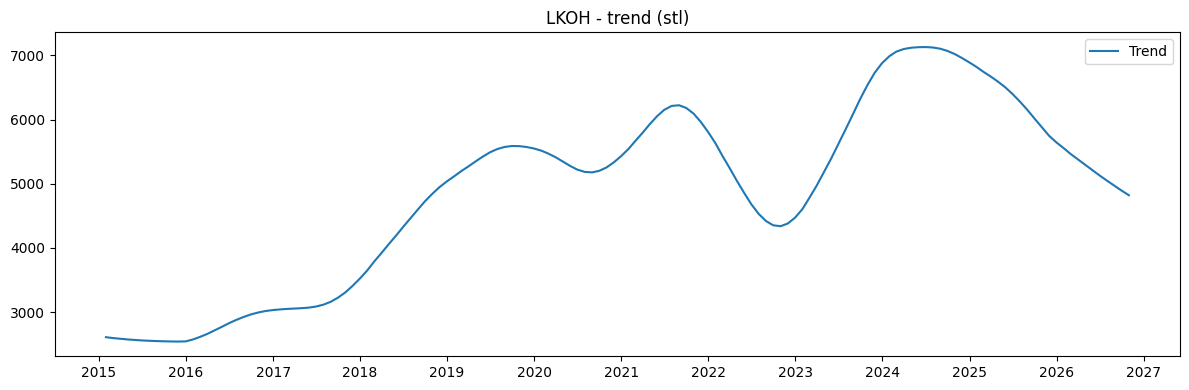

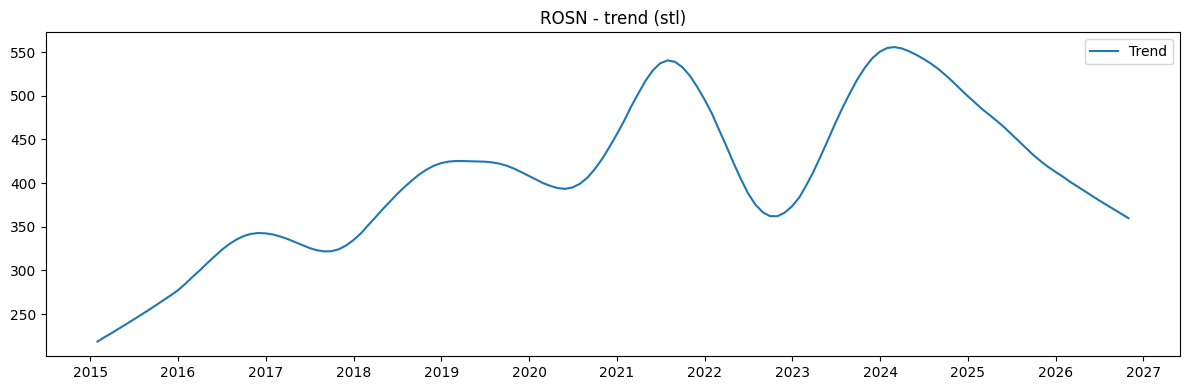

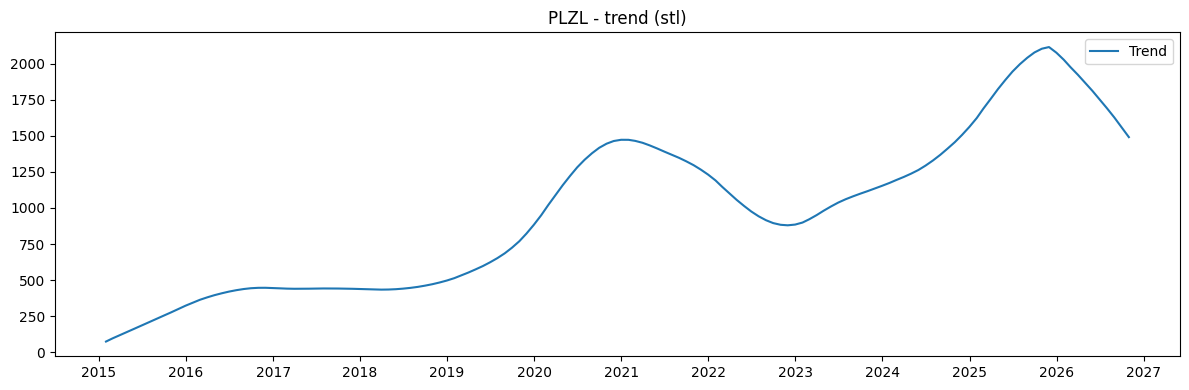

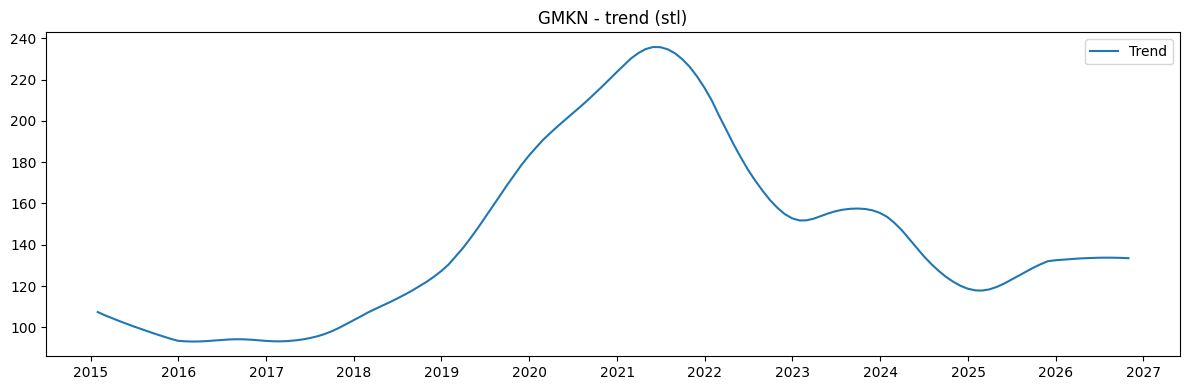

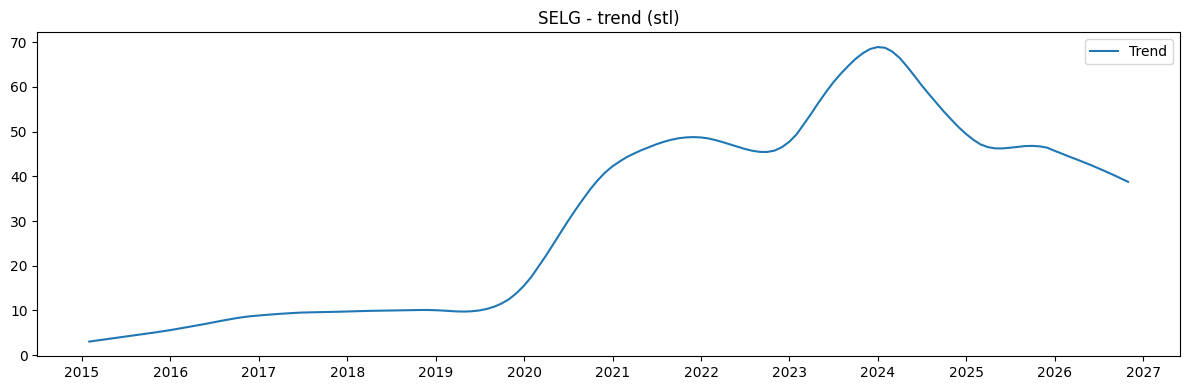

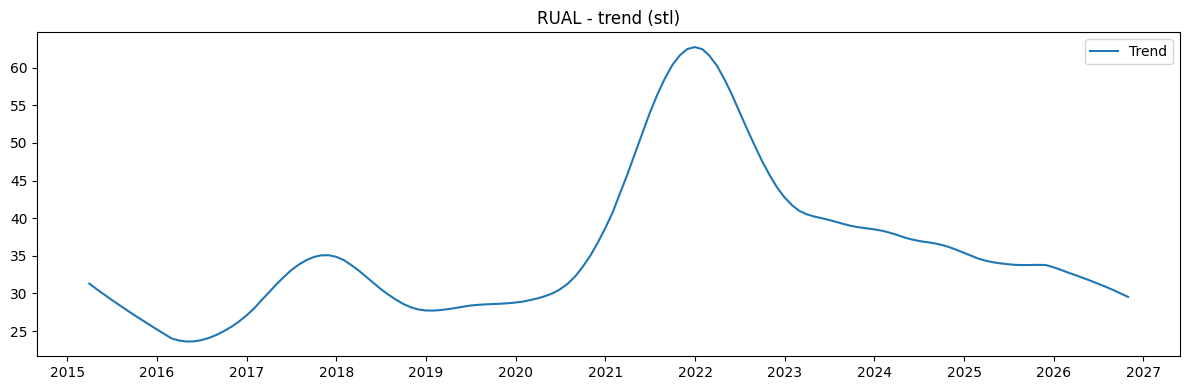

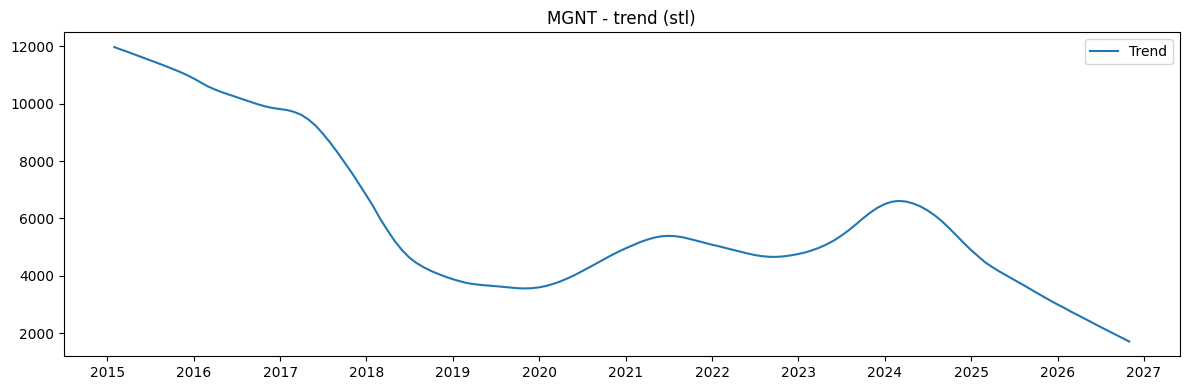

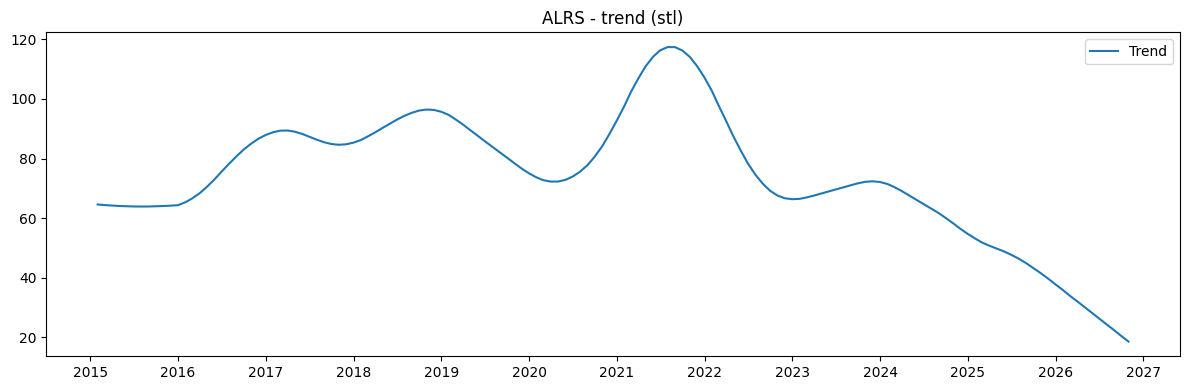

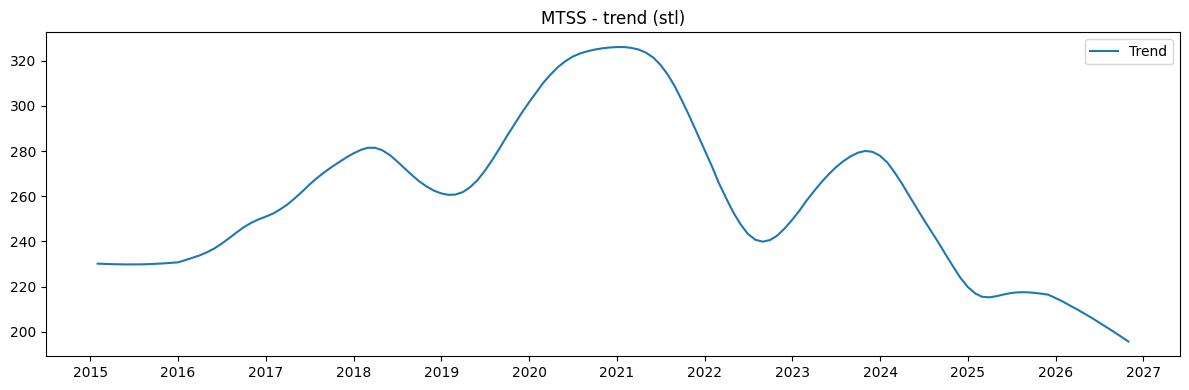

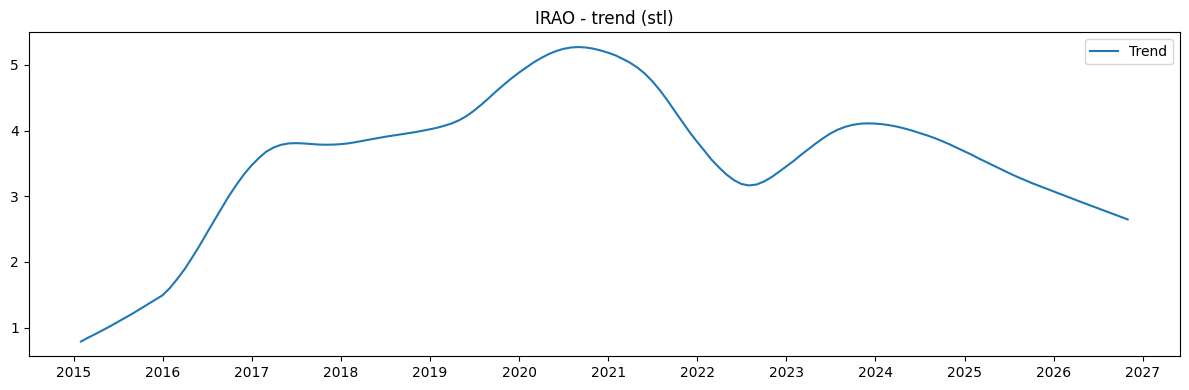

In [9]:
tickers_lst = ['SBER', 'GAZP', 'VTBR', 'LKOH',
                        'ROSN', 'PLZL', 'GMKN',
                        'SELG', 'RUAL', 'MGNT', 'ALRS', 'MTSS', 'IRAO']
for tick in tickers_lst:
    check_trend_stl(tick, df_month)


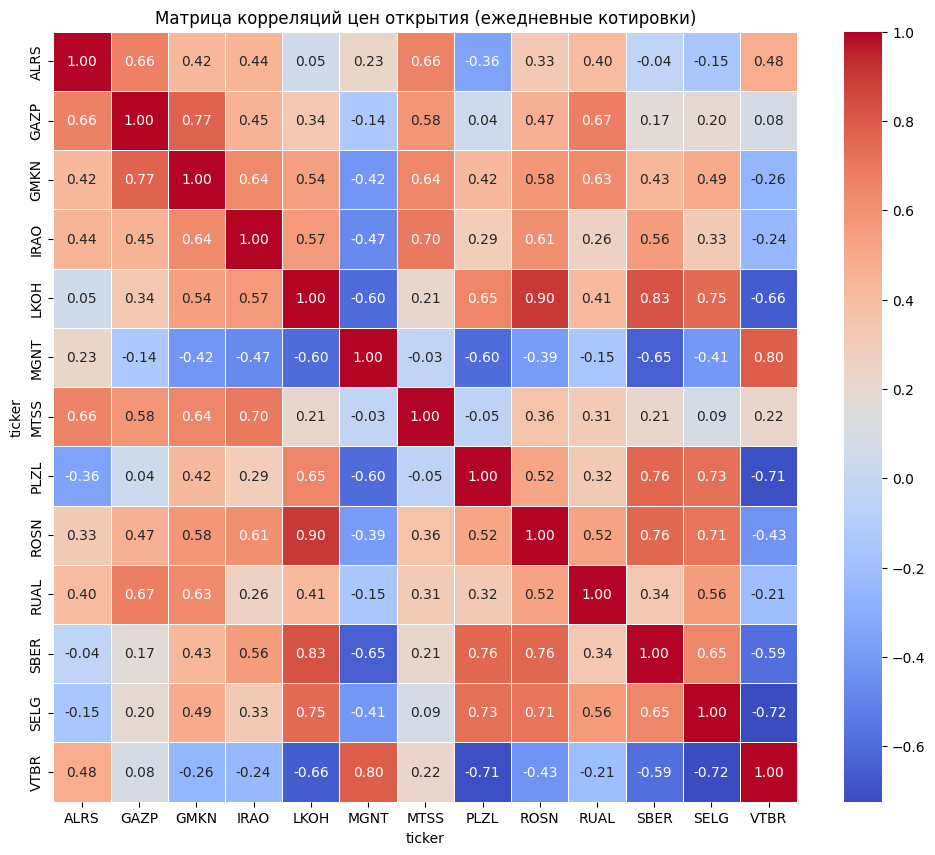

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Преобразуем данные в широкий формат: даты по строкам, тикеры по колонкам
prices_open = df.pivot( columns='ticker', values='open')

corr_matrix = prices_open.corr()

# 3. Визуализируем с помощью тепловой карты
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Матрица корреляций цен открытия (ежедневные котировки)')
plt.show()